Enter the image path:  image2.jpg


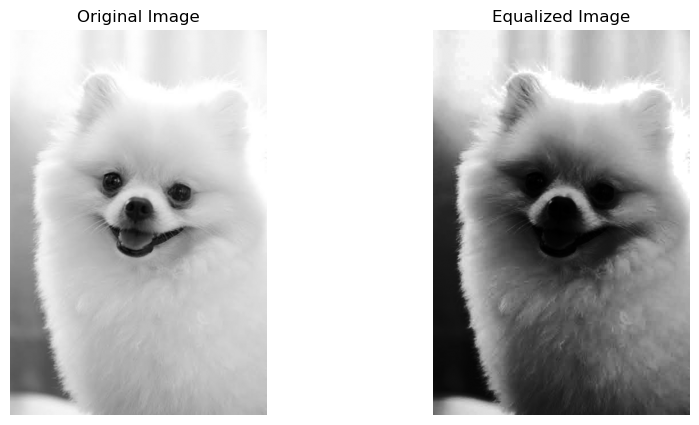

In [1]:
#Q1. Write a program to enhance the contrast of the input grayscale image 
#using histogram equalization. Display the original image and equalized image. 
import cv2
import matplotlib.pyplot as plt

# Read the input image in grayscale
image_path = input("Enter the image path: ")
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
else:
    # Apply histogram equalization
    equalized_img = cv2.equalizeHist(img)

    # Display original and equalized images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(equalized_img, cmap='gray')
    plt.title("Equalized Image")
    plt.axis("off")

    plt.show()




Enter input image path:  image2.jpg
Enter reference image path:  image1.jpg


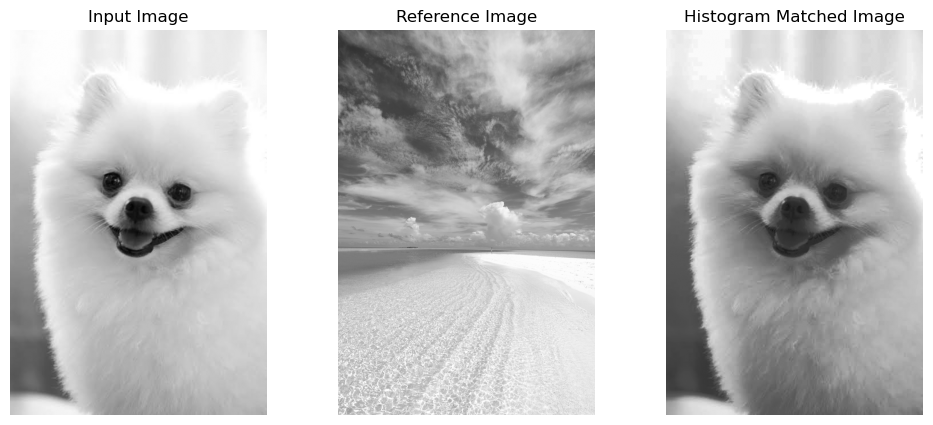

In [2]:
#Write a program to perform histogram matching of the input image with 
#that of reference image using histogram equalization

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images
input_path = input("Enter input image path: ")
reference_path = input("Enter reference image path: ")

input_img = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)
reference_img = cv2.imread(reference_path, cv2.IMREAD_GRAYSCALE)

if input_img is None or reference_img is None:
    print("Error: Could not load images!")

else:
    # Calculate histograms
    hist_input, bins = np.histogram(
        input_img.flatten(), 256, [0, 256]
    )

    hist_reference, bins = np.histogram(
        reference_img.flatten(), 256, [0, 256]
    )

    # Calculate cumulative distribution functions
    cdf_input = hist_input.cumsum()
    cdf_reference = hist_reference.cumsum()

    # Normalize CDF values
    cdf_input = cdf_input / cdf_input[-1]
    cdf_reference = cdf_reference / cdf_reference[-1]

    # Create mapping between input and reference intensities
    mapping = np.interp(cdf_input, cdf_reference, np.arange(256))

    # Apply mapping to input image
    matched_img = mapping[input_img].astype(np.uint8)

    # Display images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(input_img, cmap='gray')
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(reference_img, cmap='gray')
    plt.title("Reference Image")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(matched_img, cmap='gray')
    plt.title("Histogram Matched Image")
    plt.axis("off")

    plt.show()
